# Track-G on KP-Tracer (tumor family 3454_Lkb1_All)

Track-G identifies gene modules related to several cellular attributes of the same cells. Here the two attributes are the **lineage tree** and the **location** (SubTumor label: primary lung tumors T1 and T2, and metastases in the lymph node N1, the rib cage Rib and the kidney K1) of the 1846 cells of one KP-Tracer tumor family (Yang et al. 2022, *Cell*).

This notebook reproduces the Track-G results of the KP-Tracer section of the paper:

1. load the raw data and build the inputs: 672 genes expressed in > 1 % of the cells, $K = [K_{lineage}^{1/2} \mid K_{location}^{1/2}]$
2. choose the number of components $J$ by parallel analysis ($J = 12$)
3. fit Track-G
4. relative relatedness $p_{kj}$ of every component to the two attributes, and the cell scores $KA$ (paper Fig. 3A, B)
5. lineage and location score of every gene, $s_{gk} = \sum_j p_{kj} w_{gj}$, and the top genes
6. negative controls and false-positive curves (paper Fig. 3C, D)

Run it from `tutorial/`. All outputs are written to `tutorial/results/kptracer/`. Runtime: about 30 min on one CPU, mostly the 1000 permutations of the parallel analysis and of the negative-control tests.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

TUTORIAL = Path.cwd()                                   # this notebook runs from tutorial/
if not (TUTORIAL / "kptracer" / "data_loader_kptracer.py").exists():
    raise FileNotFoundError("Run this notebook from the tutorial/ folder of the TrackG repository.")
sys.path[:0] = [str(TUTORIAL.parent / "src"), str(TUTORIAL / "kptracer")]
from Track_G import (run_parallel_analysis, plot_parallel_analysis, fit_witten_nonnegative_cca, gene_kernel_scores,
                     save_pa_cca_outputs)
from data_loader_kptracer import load_kptracer_data
import evaluation_kptracer as EK

OUT = TUTORIAL / "results" / "kptracer"
OUT.mkdir(parents=True, exist_ok=True)

# Settings of the paper
MIN_EXPR_FRAC = 0.01                                    # genes expressed in > 1 % of the cells
PA_SETTINGS = dict(n_permutations=1000, quantile=0.95, max_components=60, seed=1234, j_cap=20)
CCA_SETTINGS = dict(c_alpha=None, c_w2=None, n_restarts=15, random_seed=42, max_cca_iter=2000, cca_tolerance=1e-6,
                    require_convergence=True, require_all_components=False, verbose=False)
N_PERM_NEG = 1000                                       # permutations of each negative-control test

## 1. Data

`load_kptracer_data` reads the raw counts and the lineage tree in `tutorial/data/kptracer/`, normalizes the counts (counts per $10^4$, then $\log(1 + x)$), keeps the genes expressed in more than 1 % of the cells, standardizes every gene, and builds the two kernels:
- lineage: the depth of the lowest common ancestor of two cells, scaled to unit diagonal;
- location: 1 for two cells of the same location, 0 otherwise.

The Track-G input is the concatenation of the kernel square roots, $K = [K_{lineage}^{1/2} \mid K_{location}^{1/2}]$.

In [2]:
data = load_kptracer_data(min_expr_frac=MIN_EXPR_FRAC)       # use_sqrt=True (default): K^1/2 of each kernel
X2_np, K, KERNEL_NAMES = data["X2_np"], data["K"], data["KERNEL_NAMES"]
genes = pd.Index(data["valid_genes"]).astype(str)
cell_names, tree = data["cell_names"], data["tree"]
location = data["cell_metadata"]["SubTumor"].astype(str).to_numpy()
ATTR = [EK.ATTRIBUTE[k] for k in KERNEL_NAMES]                    # ["Lineage", "Location"]
print(f"{data['n_cells']} cells x {data['p_gene']} genes | K {K.shape} | {len(set(location))} locations")

Genes retained (std>1e-06 & expr>1.0%): 672
Total genes retained after filtering: 672 / 1249 (std>1e-06, expressed in > 1.0% of cells)


1846 cells x 672 genes | K (1846, 3692) | 13 locations


## 2. Number of components: parallel analysis

The entries of $K^\top X$ are shuffled 1000 times. $J$ is the rank of the first singular value of $K^\top X$ that falls below the 95th percentile of the same-rank singular values of the shuffled matrices.

PA (entrywise null) selects J = 12


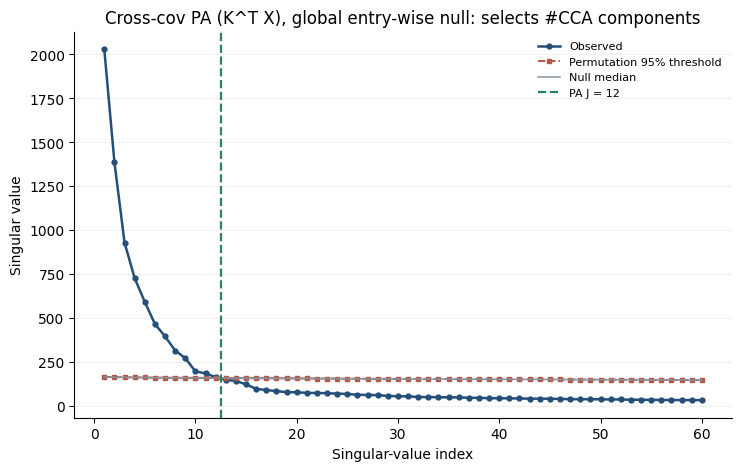

In [3]:
pa = run_parallel_analysis(X2_np, K, nulls=("entrywise",), **PA_SETTINGS)
J = pa.J
plot_parallel_analysis(pa, path=OUT / "parallel_analysis.pdf");

## 3. Fit Track-G

Components are extracted one at a time (deflation); every component is the best of 15 random restarts.

In [4]:
fit = fit_witten_nonnegative_cca(K=K, X2_np=X2_np, KERNEL_NAMES=KERNEL_NAMES, J=J, **CCA_SETTINGS)
ext = np.asarray(fit["extracted_record"], bool)
print(f"extracted components: {int(ext.sum())} / {J}")
fit["cca_diagnostics"].round(3)

extracted components: 12 / 12


,component_index,component,extracted,selected_restart,iterations,converged,objective,pearson_KA_XW,residual_fro_before,residual_fro_after,...,nnz_W2,l1_A,l1_W2,Delta_A,Delta_W2,score_Sigma_phylo,score_Sigma_subtumor,contribution_Sigma_phylo,contribution_Sigma_subtumor,winning_kernel
0,0,C_0,True,8,17,True,1169.817,0.365,2961.738,2720.922,...,390,35.623,14.892,0.0,0.0,0.537,0.844,7.546,16.694,Sigma_subtumor
1,1,C_1,True,11,8,True,1006.240,0.513,2720.922,2528.023,...,417,16.771,14.270,0.0,0.0,0.612,0.791,5.209,8.797,Sigma_subtumor
2,2,C_2,True,5,28,True,639.865,0.519,2528.023,2445.704,...,237,33.181,9.645,0.0,0.0,0.215,0.977,2.687,13.545,Sigma_subtumor
3,3,C_3,True,14,13,True,465.363,0.274,2445.704,2401.022,...,369,26.628,15.171,0.0,0.0,0.921,0.388,14.488,3.947,Sigma_phylo
4,4,C_4,True,5,12,True,436.057,0.328,2401.022,2361.093,...,228,30.965,10.952,0.0,0.0,1.000,0.000,15.876,0.000,Sigma_phylo
5,5,C_5,True,3,9,True,413.485,0.348,2361.093,2324.606,...,270,16.869,12.083,0.0,0.0,0.595,0.804,4.552,9.935,Sigma_subtumor
6,6,C_6,True,10,21,True,258.208,0.284,2324.606,2310.221,...,297,10.681,12.845,0.0,0.0,0.000,1.000,0.000,7.993,Sigma_subtumor
7,7,C_7,True,4,7,True,235.359,0.227,2310.221,2298.201,...,250,16.674,12.092,0.0,0.0,0.001,1.000,0.001,15.367,Sigma_subtumor
8,8,C_8,True,4,31,True,222.638,0.274,2298.201,2287.391,...,267,12.824,12.751,0.0,0.0,0.000,1.000,0.000,11.319,Sigma_subtumor
9,9,C_9,True,5,20,True,200.781,0.411,2287.391,2278.562,...,164,25.544,8.837,0.0,0.0,0.145,0.989,0.804,19.770,Sigma_subtumor


## 4. Relatedness of the components to the two attributes, and cell scores

$p_{kj} = \|\alpha_j^{(k)}\|_2 / \sum_\ell \|\alpha_j^{(\ell)}\|_2$ is the relative relatedness of component $j$ to attribute $k$; the attribute with the largest $p_{kj}$ dominates the component (Supplementary Fig. S1). The cell scores $KA$ of the location-related components are shown with the cells ordered by location (paper Fig. 3A), those of the lineage-related components with the cells ordered by the lineage tree (Fig. 3B).

{'Lineage': ['C3', 'C4'], 'Location': ['C0', 'C1', 'C2', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11']}


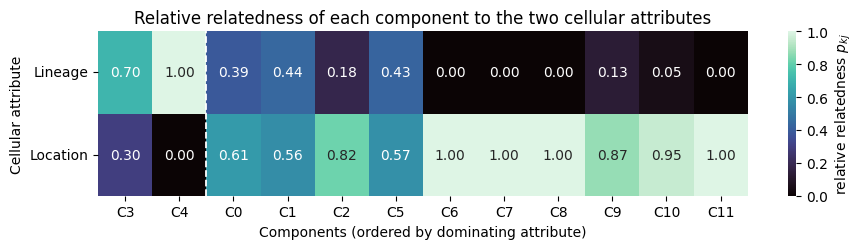

In [5]:
p, s = gene_kernel_scores(fit["W2_matrix"], fit["all_scores"], genes, ATTR)   # p: attributes x components
p = p.loc[:, ext]
dominant = p.idxmax()                                              # dominating attribute of every component
print({a: list(dominant.index[dominant == a]) for a in ATTR})
EK.plot_relatedness(p, path=OUT / "relative_relatedness.pdf");

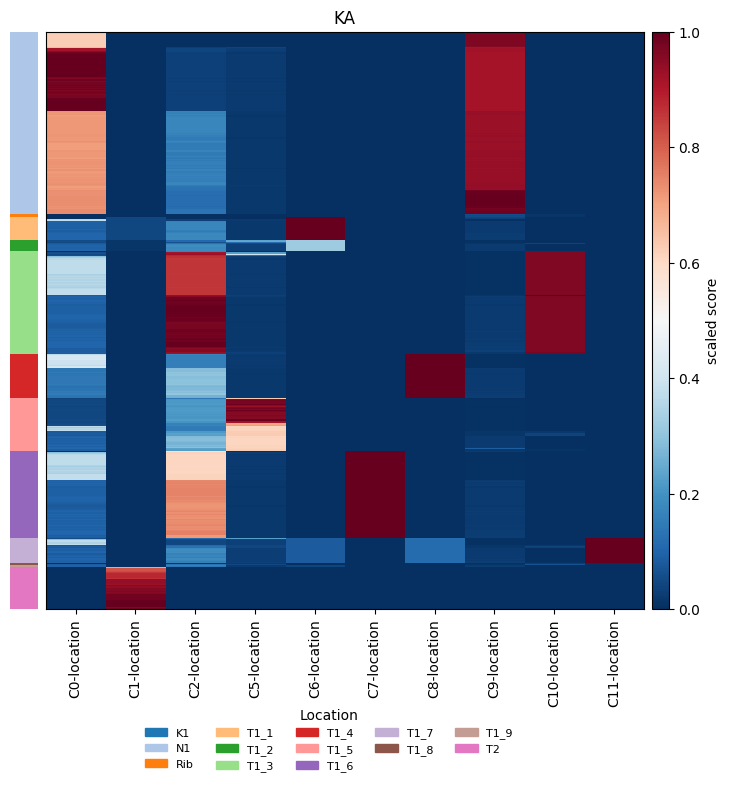

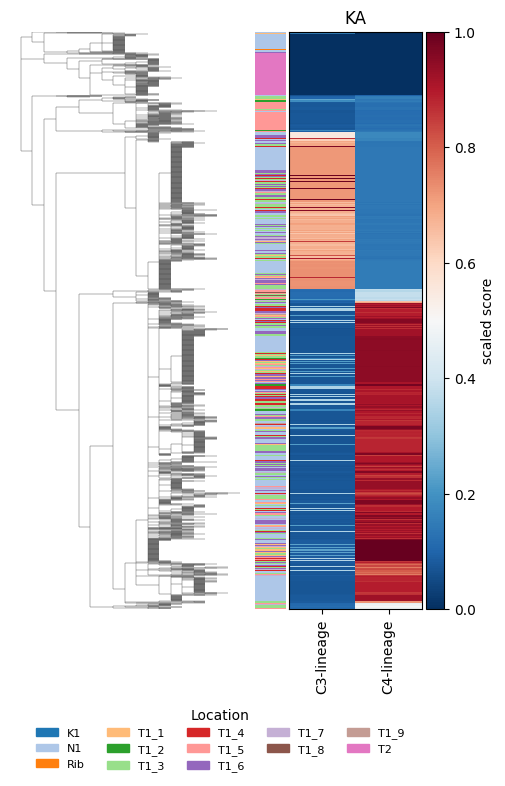

In [6]:
KA = pd.DataFrame(fit["U_score_matrix"][:, ext], index=cell_names, columns=p.columns)   # cell scores K @ A
loc_comps, lin_comps = dominant.index[dominant == "Location"], dominant.index[dominant == "Lineage"]
EK.plot_scores_by_location(KA[loc_comps].rename(columns=lambda c: f"{c}-location"), location,
                           path=OUT / "KA_location_components.pdf")
EK.plot_scores_by_tree(KA[lin_comps].rename(columns=lambda c: f"{c}-lineage"), tree, cell_names, location,
                       path=OUT / "KA_lineage_components.pdf");

## 5. Gene scores

The score of gene $g$ for attribute $k$ is $s_{gk} = \sum_j p_{kj}\, w_{gj}$: a gene ranks high for an attribute when it has large weights in the components dominated by this attribute.

In [7]:
s.assign(dominant=s.idxmax(axis=1)).to_csv(OUT / "gene_scores.csv")
top = pd.DataFrame({a: s[a].sort_values(ascending=False, kind="stable").index[:20] for a in ATTR},
                   index=pd.RangeIndex(1, 21, name="rank"))
top.to_csv(OUT / "top20_genes.csv")
top

,Lineage,Location
rank,,
1,Clu,Sftpc
2,Cd24a,Clu
3,Stmn2,Aldoa
4,Krt18,Pgk1
5,Onecut2,Lyz2
6,Ube2b,Ctsl
7,Cldn3,Rpl37
8,Sftpc,H2-Aa
9,Krt20,Rpl35a


## 6. Negative controls and false-positive curves

There is no ground truth for which attribute drives a gene. Instead, a gene is a **negative control** of an attribute when its expression shows no structure along this attribute once the other attribute is fixed (Supplementary Section "Conditional permutation tests"):
- **lineage**: Moran's I on a kNN graph of the lineage kernel, against a null that permutes the expression among cells of the same location (145 genes with $p > 0.5$);
- **location**: Moran's I on the graph of cells of the same location, against a null that permutes the expression among sister leaves of the tree, which keeps the lineage exactly (165 genes with $p > 0.5$ among the genes the null can change).

A good ranking for an attribute places few of its negative controls at the top (fewer false positives).

In [9]:
neg_lineage = EK.lineage_negative_controls(X2_np, data["kernels_raw"]["Sigma_phylo"], tree, cell_names, location,
                                           genes, n_perm=N_PERM_NEG)
neg_location = EK.location_negative_controls(X2_np, tree, cell_names, location, genes, n_perm=N_PERM_NEG)
pd.concat({"lineage": neg_lineage, "location": neg_location}, axis=1).to_csv(OUT / "negative_controls.csv")
negatives = {"Lineage": neg_lineage["negative"], "Location": neg_location["negative"]}
print("negative controls:", {a: int(v.sum()) for a, v in negatives.items()})

negative controls: {'Lineage': 145, 'Location': 165}


,top 20,top 50,top 100,top 200,negatives
Lineage,1,2,4,12,145
Location,0,0,2,12,165


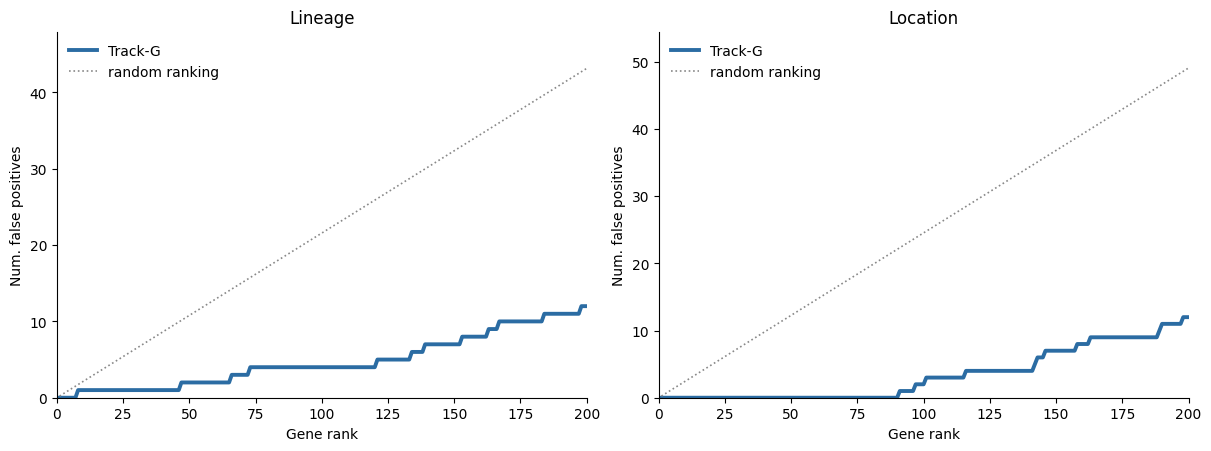

In [10]:
EK.plot_fp_curves(s, negatives, top=200, path=OUT / "fp_curves.pdf")
EK.negatives_in_top(s, negatives)

## 7. Save

One pickle with the labelled outputs of the fit (`pd.read_pickle`): gene loadings `W2`, kernel coefficients `A`, cell scores `KA` and `XW`, per-component diagnostics, the PA spectrum and the settings.

In [11]:
save_pa_cca_outputs(OUT / "trackg_kptracer.pkl", fit, data, pa=pa, settings=CCA_SETTINGS)
p.to_csv(OUT / "relative_relatedness.csv")
print("outputs in", OUT)

outputs in /home/yjunfeng/linage_project/TrackG/tutorial/results/kptracer
